# 03 Model results: does a fitted model beat the obvious rule?

Target: any serious event (vacate order, emergency-repair charge, AEP selection or new litigation) in the next 12 months.
Validation: strictly temporal walk-forward folds with a 12 month purge gap; the final test slice is the last four snapshots (2025-01-01 to 2025-10-01), scored once.
Intervals are cluster bootstraps by building. Source tables: `reports/phase3/*.csv`. Full write-up: [`docs/modeling_phase3.md`](../docs/modeling_phase3.md).

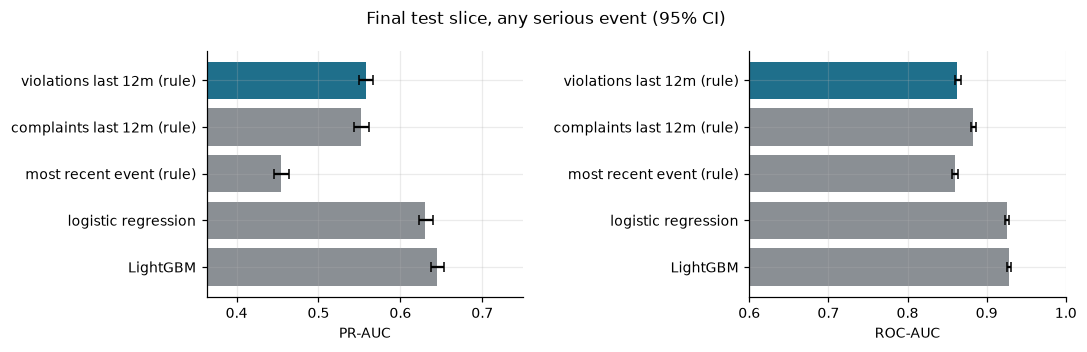

,model,PR-AUC,pr_lo,pr_hi,ROC-AUC,roc_lo,roc_hi
0,violations last 12m (rule),0.558,0.550,0.567,0.863,0.860,0.867
1,complaints last 12m (rule),0.552,0.543,0.562,0.883,0.880,0.886
2,most recent event (rule),0.454,0.446,0.464,0.860,0.857,0.864
3,logistic regression,0.630,0.622,0.639,0.925,0.923,0.928
4,LightGBM,0.645,0.638,0.653,0.928,0.926,0.931


In [1]:
from nbutil import *
m = pd.read_csv(REPORTS / "phase3" / "metrics_test_ci.csv")
def get(model, fset, metric, target="label_serious_any", slc="all"):
    r = m[(m.target == target) & (m.slice == slc) & (m.model == model) & (m.fset == fset) & (m.metric == metric)].iloc[0]
    return r.point, r.lo, r.hi
rows = [("violations last 12m (rule)", "rule_viol_12m", "-"), ("complaints last 12m (rule)", "rule_complaints_12m", "-"), ("most recent event (rule)", "rule_last_event", "-"),
        ("logistic regression", "logit", "all"), ("LightGBM", "lgb", "all")]
tab = pd.DataFrame([(n, *get(mo, fs, "pr_auc"), *get(mo, fs, "roc_auc")) for n, mo, fs in rows],
                   columns=["model", "PR-AUC", "pr_lo", "pr_hi", "ROC-AUC", "roc_lo", "roc_hi"])
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
for a, (c, lo, hi) in zip(ax, [("PR-AUC", "pr_lo", "pr_hi"), ("ROC-AUC", "roc_lo", "roc_hi")]):
    a.barh(tab.model[::-1], tab[c][::-1], xerr=[(tab[c] - tab[lo])[::-1], (tab[hi] - tab[c])[::-1]], color=[BLUE, GREY, GREY, GREY, GREY][::-1], capsize=3)
    a.set_xlabel(c); a.set_xlim(tab[c].min() * 0.8 if c == "PR-AUC" else 0.6, 1 if c == "ROC-AUC" else 0.75)
plt.suptitle("Final test slice, any serious event (95% CI)"); plt.tight_layout(); plt.show()
tab.round(3)

LightGBM beats each simple rule on both PR-AUC and ROC-AUC, but the rules are a **strong** baseline: enforcement is rule driven off violation counts, so the label is partly circular with it. Most of the gain is already available to a logistic regression.

## It wins everywhere, not just on average

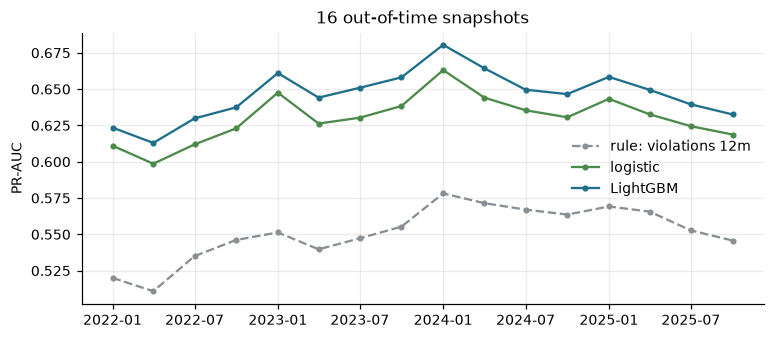

LightGBM beats the rule at 16 of 16 snapshots; PR-AUC gap 0.083 to 0.110


In [2]:
ps = pd.read_csv(REPORTS / "phase3" / "per_snapshot.csv", parse_dates=["snapshot_date"])
fig, ax = plt.subplots(figsize=(8, 3.2))
for name, mo, fs, col, ls in [("rule: violations 12m", "rule_viol_12m", "-", GREY, "--"), ("logistic", "logit", "all", GREEN, "-"), ("LightGBM", "lgb", "all", BLUE, "-")]:
    d = ps[(ps.model == mo) & (ps.fset == fs)].sort_values("snapshot_date")
    ax.plot(d.snapshot_date, d.pr_auc, ls, color=col, marker="o", ms=3, label=name)
ax.set_ylabel("PR-AUC"); ax.set_title("16 out-of-time snapshots"); ax.legend(frameon=False); plt.show()
a = ps[(ps.model == "lgb") & (ps.fset == "all")].set_index("snapshot_date").pr_auc
b = ps[(ps.model == "rule_viol_12m")].set_index("snapshot_date").pr_auc
print(f"LightGBM beats the rule at {(a > b).sum()} of {len(a)} snapshots; PR-AUC gap {((a - b).min()):.3f} to {((a - b).max()):.3f}")

## What each feature group adds (ablation)

Removing complaint-derived features costs little; removing violation features costs more; removing both still beats the rule, narrowly. The groups substitute for each other.

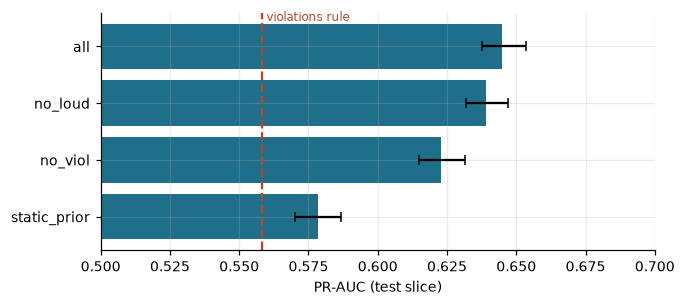

,feature set,PR-AUC,lo,hi
0,all,0.645,0.638,0.653
1,no_loud,0.639,0.632,0.647
2,no_viol,0.623,0.615,0.631
3,static_prior,0.578,0.570,0.587


In [3]:
ab = pd.DataFrame([(fs, *get("lgb", fs, "pr_auc")) for fs in ["all", "no_loud", "no_viol", "static_prior"]], columns=["feature set", "PR-AUC", "lo", "hi"])
rule = get("rule_viol_12m", "-", "pr_auc")[0]
fig, ax = plt.subplots(figsize=(6.5, 2.8))
ax.barh(ab["feature set"][::-1], ab["PR-AUC"][::-1], xerr=[(ab["PR-AUC"] - ab.lo)[::-1], (ab.hi - ab["PR-AUC"])[::-1]], color=BLUE, capsize=3)
ax.axvline(rule, color=RED, ls="--"); ax.text(rule, 3.45, " violations rule", color=RED, fontsize=8); ax.set_xlim(0.5, 0.7); ax.set_xlabel("PR-AUC (test slice)")
plt.show(); ab.round(3)

## Where the model helps most: buildings the rule would not flag

`quiet` = no class C violation and at most 2 violations last year (82% of rows). `clean_record` is stricter. The rule is almost useless there; the model keeps some signal, mostly from static building attributes.

In [4]:
rows = []
for s in ["all", "quiet", "clean_record"]:
    rows.append((s, get("rule_viol_12m", "-", "roc_auc", slc=s)[0], get("lgb", "all", "roc_auc", slc=s)[0], get("lgb", "all", "pr_auc", slc=s)[0], get("lgb", "all", "base_rate", slc=s)[0]))
pd.DataFrame(rows, columns=["slice", "ROC-AUC rule", "ROC-AUC LightGBM", "PR-AUC LightGBM", "base rate"]).round(3)

,slice,ROC-AUC rule,ROC-AUC LightGBM,PR-AUC LightGBM,base rate
0,all,0.863,0.928,0.645,0.085
1,quiet,0.531,0.830,0.138,0.021
2,clean_record,0.500,0.755,0.033,0.007


## Calibration

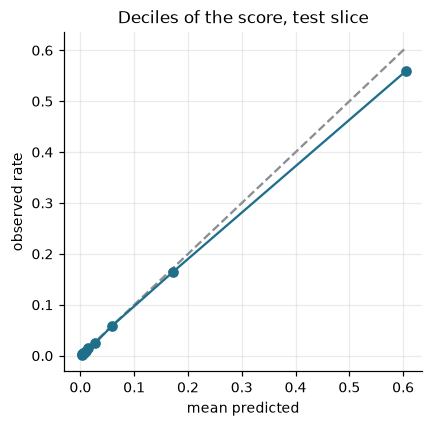

In [5]:
c = pd.read_csv(REPORTS / "phase3" / "calibration_test.csv")
c = c[(c.target == "label_serious_any") & (c.model == "lgb") & (c.fset == "all")]
fig, ax = plt.subplots(figsize=(4.2, 4))
ax.plot([0, c.mean_pred.max()], [0, c.mean_pred.max()], color=GREY, ls="--"); ax.plot(c.mean_pred, c.observed, "o-", color=BLUE)
ax.set_xlabel("mean predicted"); ax.set_ylabel("observed rate"); ax.set_title("Deciles of the score, test slice"); plt.show()

Probabilities are well calibrated (ECE about 0.006) and slightly high, because the test base rate (8.5%) is below the training average. No recalibration was applied.

## What the score is made of (SHAP shares)

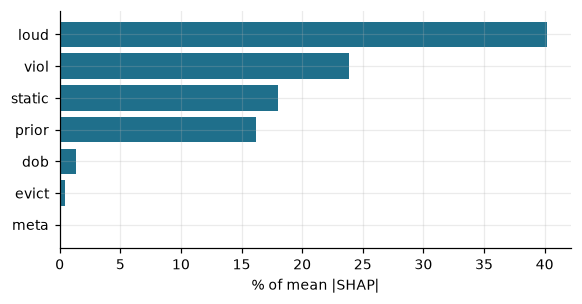

In [6]:
sg = pd.read_csv(REPORTS / "phase3" / "shap_groups.csv")
sg = sg[sg.fset == "all"].sort_values("share")
fig, ax = plt.subplots(figsize=(6, 2.8)); ax.barh(sg.group, 100 * sg.share, color=BLUE); ax.set_xlabel("% of mean |SHAP|"); plt.show()

Complaints take 40% and violations 24%, but because those two are correlated SHAP overstates what each uniquely adds; the ablation above is the cleaner evidence.

## Figures from the pipeline

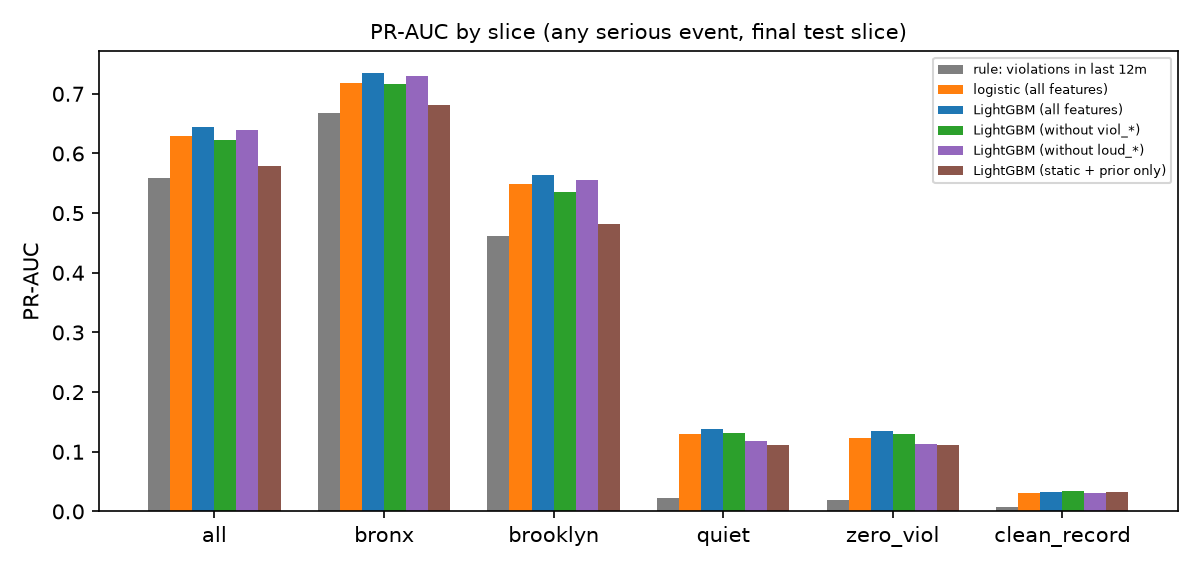

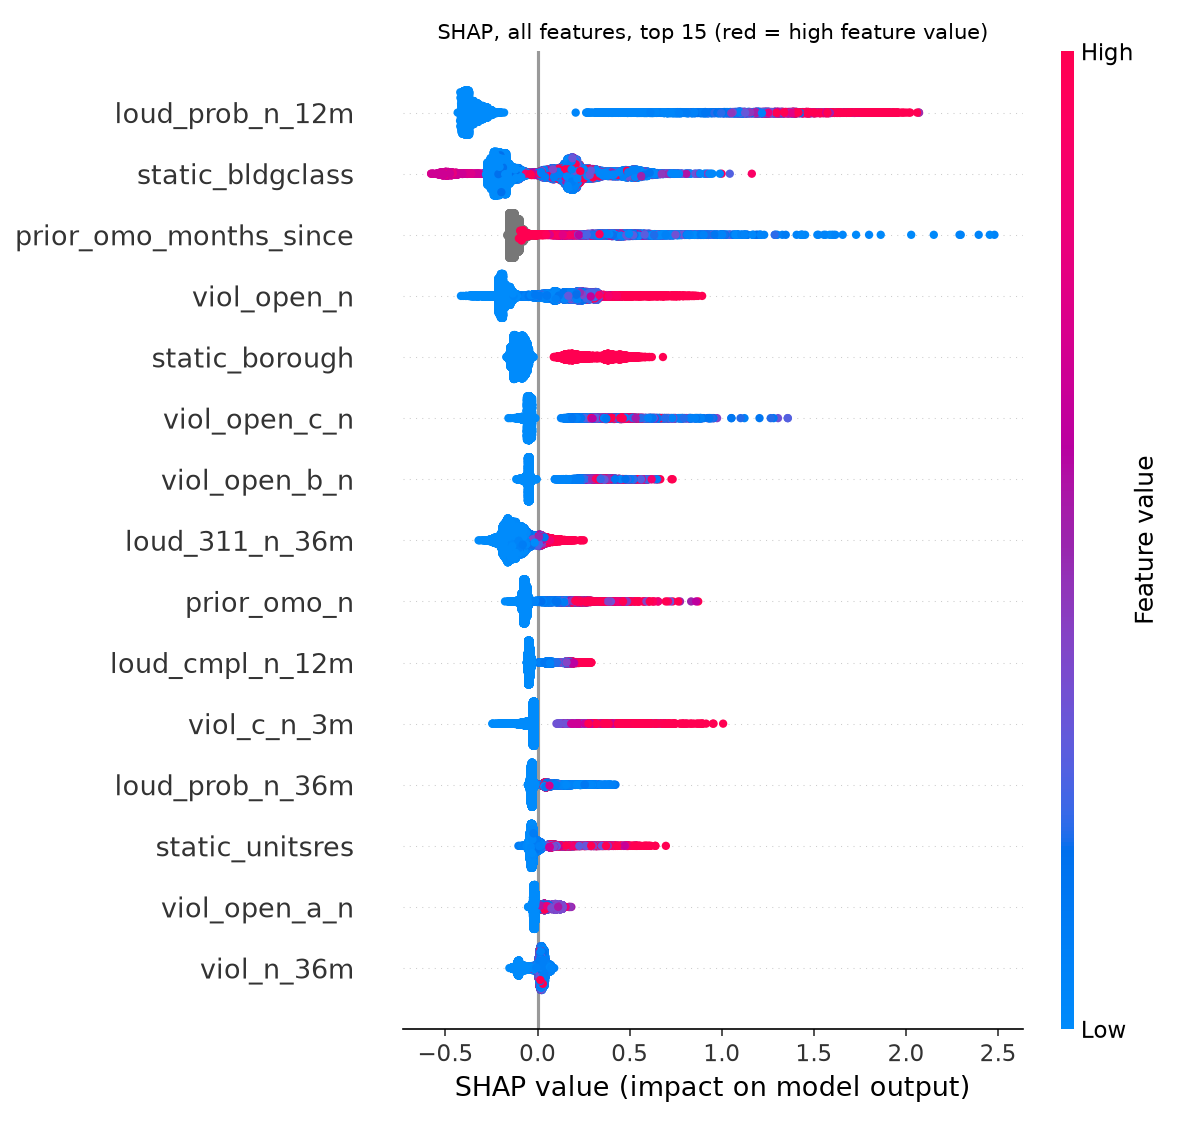

In [7]:
from IPython.display import Image, display
for f in ["slices.png", "shap_beeswarm.png"]:
    display(Image(filename=str(REPORTS / "phase3" / "figures" / f), width=700))

## What this does and does not show
- **Does:** a model out-ranks the naive violation rule, out of time, at all 16 snapshots, and generalises to community districts it has not seen (held-out districts leave ROC-AUC unchanged at 0.93).
- **Does not:** it predicts city *enforcement events*, not physical condition. A high score mostly means the city is already engaged with the building. Borough and building class are strong static features and need a fairness review before any use for targeting.
